# 05 - Sampling strategies and sensitivity analysis

This notebook compares sampling strategies and then runs sensitivity analysis to understand which parameters drive performance.

In practical terms, we will move through preparation, configuration, execution, and verification so every transition in the workflow stays explicit.
As the notebook progresses, each code cell is introduced with context first, then the call itself, and finally quick guidance on how to interpret the result.

Workflow roadmap:
- Preparation: imports, path configuration, and baseline model loading.
- Configuration: output selection, parameter definitions, and problem setup.
- Execution and review: simulation or optimization calls followed by targeted checks.

Main classes, methods, and functions used in this notebook:
- `ParametricSimulation.sampling_morris`
- `ParametricSimulation.sampling_sobol`
- `ParametricSimulation.run_sensitivity_analysis`
- `ParametricSimulation.run_sensitivity_analysis_by_epw`
- `WorkspaceArtifactCleaner`
- `ef.get_building`
- `ParametricSimulation`
- `parametric.discover_available_outputs`
- `parametric.select_outputs`
- `parametric.apply_outputs_preflight`

Narrative structure used in this notebook:
- Each code cell is preceded by an explanatory markdown block.
- Section headings are contextual to the current notebook and execution block.
- Key arguments are described before they are used in code.
- Execution-oriented cells may include a follow-up markdown note to help interpret results.

## Sampling and sensitivity: import workflow dependencies

We start by importing the APIs required for this notebook block.

Keeping imports explicit at the top of each topic notebook makes selective reruns safer when you jump between sections of the series.

What to verify right after running this cell:
- Review execution output and proceed when values look consistent with the workflow intent.

`PROCESSES` is the number of simulations run in parallel: half of the logical CPUs by default.

In [1]:
import os
from pathlib import Path

import accim
import pandas as pd
from IPython.display import Image, display
from besos import eppy_funcs as ef
from accim.utils import WorkspaceArtifactCleaner
from accim.parametric_and_optimisation.main import ParametricSimulation

pd.set_option("display.max_columns", 160)

# Simulations run in parallel: half of the logical CPUs.
PROCESSES = max(1, (os.cpu_count() or 2) // 2)


## Sampling and sensitivity: capture baseline workspace state for cleanup

We initialize artifact tracking so generated files can be reviewed and cleaned in a controlled way.

This is especially useful in iterative notebook sessions where repeated runs can quickly accumulate temporary folders and CSV files.

`reduce_runtime` also changes the run period, to 1 January by default, so its run period arguments keep the full year: the results stay annual. `Run_Simulation_for_Sizing_Periods = "No"` keeps the design days of the sample model out of the annual results (they are still used to size the HVAC system).

Key arguments used in this cell and why they matter:
- `workspace_root`: defines this setting for the current call.
- `idf_object`: defines this setting for the current call.
- `timesteps`: defines this setting for the current call.
- `building`: loaded IDF model used in this workflow.
- `parameters_type`: parameter family used in the simulation setup.
- `epws`: list of EPW weather files used to run scenarios.
- `output_freqs`: time frequency requested for outputs.

Variables created in this cell:
- `PROJECT_ROOT`: reused in subsequent workflow blocks.
- `idf_file`: reused in subsequent workflow blocks.
- `epw_list`: reused in subsequent workflow blocks.
- `RESULTS_DIRNAME`: reused in subsequent workflow blocks.
- `artifact_cleaner`: reused in subsequent workflow blocks.
- `baseline_files`: reused in subsequent workflow blocks.
- `building`: reused in subsequent workflow blocks.
- `parametric`: reused in subsequent workflow blocks.

The sensitivity analysis is run with one weather file, to keep the run below short.

What to verify right after running this cell:
- Confirm these objects are available for the next block: `PROJECT_ROOT`, `idf_file`, `epw_list`, `RESULTS_DIRNAME`.

In [2]:
PROJECT_ROOT = Path.cwd()

idf_file = "OSM_TestResidentialUnit_v01_onlygeometry_SchNatVent_v2520_high_performance.idf"
epw_list = ["Seville.epw"]
RESULTS_DIRNAME = "nb05_sampling_sensitivity_results"

artifact_cleaner = WorkspaceArtifactCleaner(workspace_root=PROJECT_ROOT)
baseline_files = artifact_cleaner.capture_initial_state()
print("Baseline file count:", len(baseline_files))

building = ef.get_building(idf_file)
accim.utils.reduce_runtime(
    idf_object=building,
    timesteps=2,
    runperiod_begin_month=1,
    runperiod_begin_day_of_month=1,
    runperiod_end_month=12,
    runperiod_end_day_of_month=31,
)
building.idfobjects["SimulationControl"][0].Run_Simulation_for_Sizing_Periods = "No"

parametric = ParametricSimulation(
	building=building,
	parameters_type="accim custom model",
	epws=epw_list,
	output_freqs=["hourly"],
)


Baseline file count: 571


Solar distribution has been set to MinimalShadowing.
Shading Calculation Update Frequency was previously set to 20 days, and it has been modified to 20 days.
Maximum Figures in Shadow Overlap Calculations was previously set to 15000 days, and it has been modified to 200 days.
Number of Timesteps per Hour was previously set to 6 days, and it has been modified to 2 days.

--------------------------------------------------------
Adaptive-Comfort-Control-Implemented Model (ACCIM) v0.7.8
--------------------------------------------------------

This tool allows to apply adaptive setpoint temperatures. 
For further information, please read the documentation: 
https://accim.readthedocs.io/en/master/
For a visual understanding of the tool, please visit the following jupyter notebooks:
-    Using addAccis() to apply adaptive setpoint temperatures
https://accim.readthedocs.io/en/master/jupyter_notebooks/addAccis/using_addAccis.html
-    Using rename_epw_files() to rename the EPWs for proper data

Cooling Fanger comfort setpoint: Always  0.1 Schedule has been added
Zone CO2 setpoint: Always 900ppm Schedule has been added
Min CO2 concentration: Always 600ppm Schedule has been added
Generic contaminant setpoint: Always 0.5ppm Schedule has been added
Air distribution effectiveness (always 1) Schedule has been added
VRF Heating Cooling (Northern Hemisphere) Schedule has been added
DefaultFanEffRatioCurve Curve:Cubic Object has been added
VRFTUCoolCapFT Curve:Cubic Object has been added
VRFTUHeatCapFT Curve:Cubic Object has been added
VRFCoolCapFTBoundary Curve:Cubic Object has been added
VRFCoolEIRFTBoundary Curve:Cubic Object has been added
CoolingEIRLowPLR Curve:Cubic Object has been added
VRFHeatCapFTBoundary Curve:Cubic Object has been added
VRFHeatEIRFTBoundary Curve:Cubic Object has been added
HeatingEIRLowPLR Curve:Cubic Object has been added
DefaultFanPowerRatioCurve Curve:Exponent Object has been added
DXHtgCoilDefrostEIRFT Curve:Biquadratic Object has been added
VRFCoolCap

AHST_Sch_Floor_2_Residential_Living_Occupants Schedule has been added
ACST_Sch_Floor_2_Residential_Living_Occupants Schedule has been added
Added - SetComfTemp Program
Added - CountHours_Floor_1_Residential_Living_Occupants Program
Added - CountHours_Floor_2_Residential_Living_Occupants Program
Added - SetAppLimits Program
Added - ApplyCAT Program
Added - SetAST_Master Program with 109 lines


Added - 46 per-ComfStand SetAST subprograms
Added - SetAST Program (base program that calls SetAST_Master)
Added - SetASTnoTol Program
Added - CountHoursNoApp_Floor_1_Residential_Living_Occupants Program
Added - SetGeoVarFloor_1_Residential_Living_Occupants Program
Added - CountHoursNoApp_Floor_2_Residential_Living_Occupants Program
Added - SetGeoVarFloor_2_Residential_Living_Occupants Program
Added - SetInputData Program
Added - SetVOFinputData Program
Added - SetVST Program
Added - ApplyAST_Floor_1_Residential_Living_Occupants Program
Added - ApplyAST_Floor_2_Residential_Living_Occupants Program
Added - Comfort Temperature Output Variable
Added - Adaptive Cooling Setpoint Temperature Output Variable
Added - Adaptive Heating Setpoint Temperature Output Variable
Added - Adaptive Cooling Setpoint Temperature_No Tolerance Output Variable
Added - Adaptive Heating Setpoint Temperature_No Tolerance Output Variable
Added - z_test_ComfStand Output Variable
Added - z_test_ACSTaul Output Variab

## Sampling and sensitivity: discover available meter and variable outputs

Inspect available meters and variables before selecting valid outputs.

Before selecting outputs, we inspect what meters and variables are currently available. That discovery step reduces mistakes when requesting objective or analysis outputs.

Key arguments used in this cell and why they matter:
- `reduce_sim_time`: enables a fast scan mode when discovering outputs.
- `prefer`: preferred backend for output discovery.
- `meters`: energy meters to include as outputs.
- `match`: matching rule used to select outputs.
- `on_missing`: behavior when a requested output is missing.
- `suggest`: shows suggestions when no exact match is found.
- `df_meters_sel`: table of selected meters to apply to the IDF.
- `df_vars_sel`: table of selected variables to apply to the IDF.
- `clean_mode`: cleanup mode applied before adding outputs.
- `validate_before_apply`: whether to validate before editing the IDF.
- `validate_after_apply`: whether to validate after editing the IDF.
- `df_output_meter`: final meter table used by the simulation.

Variables created in this cell:
- `df_meters_available`: reused in subsequent workflow blocks.
- `_`: reused in subsequent workflow blocks.
- `df_meters_sel`: reused in subsequent workflow blocks.
- `accis_parameters`: reused in subsequent workflow blocks.

What to verify right after running this cell:
- Check that the discovered meter/variable tables are not unexpectedly empty.
- Confirm the reported discovery source matches your preferred backend.

In [3]:
available_outputs = parametric.discover_available_outputs(
	reduce_sim_time=True,
	prefer="testsimeplus",
)
df_meters_available = available_outputs["meters"]
selection = parametric.select_outputs(
	meters=["Heating:Electricity", "Cooling:Electricity"],
	match="case_insensitive",
	on_missing="raise",
	suggest=True,
)
df_meters_sel = selection["meters"]

parametric.apply_outputs_preflight(
	df_meters_sel=df_meters_sel,
	df_vars_sel=None,
	clean_mode="all",
	validate_before_apply=False,
	validate_after_apply=True,
	on_missing="raise",
)
parametric.set_output_readers(df_output_meter=df_meters_sel)

accis_parameters = {
	"CustAST_m": (0.15, 0.95),
	"CustAST_n": (8, 23),
	"CustAST_ASToffset": (1.0, 6.0),
}
parametric.set_parameters(accis_params_dict=accis_parameters)
parametric.set_problem(minimize_outputs=[True, True])

print("Configured parameters:", list(accis_parameters.keys()))
print("Configured outputs:", parametric.problem.names("outputs"))


Solar distribution is already set to MinimalShadowing, therefore no action has been performed.
Shading Calculation Update Frequency was previously set to 20 days, and it has been modified to 20 days.
Maximum Figures in Shadow Overlap Calculations was previously set to 200 days, and it has been modified to 200 days.
Number of Timesteps per Hour was previously set to 2 days, and it has been modified to 2 days.


The following parameters are not included in the parameters to be set, and have not been defined yet (i.e. the value is 0): ['ACSTaul', 'ACSTall', 'AHSTaul', 'AHSTall']
Configured parameters: ['CustAST_m', 'CustAST_n', 'CustAST_ASToffset']
Configured outputs: ['Heating:Electricity', 'Cooling:Electricity']


## Sampling and sensitivity: build Morris and Sobol sampling plans

Prepare the sampling strategy or explicit dataframe of cases to run.

The Sobol plan (Saltelli sampling) is only drawn to show its size: with second-order indices it needs `num_samples x (2 x parameters + 2)` simulations per EPW, so it is not simulated here. The Morris plan is drawn last, because the sensitivity analysis uses the settings of the last sampling method.

A Morris plan is made of trajectories of `parameters + 1` points, and different trajectories may share points. `run_parametric_simulation` simulates each distinct point once and returns one row per point of the plan, in its order, which is what the analysis needs.

Key arguments used in this cell and why they matter:
- `num_samples`: number of samples in the sampling plan.
- `num_levels`: number of levels for Morris sampling.

Variables created in this cell:
- `morris_df`: reused in subsequent workflow blocks.
- `sobol_df`: reused in subsequent workflow blocks.

What to verify right after running this cell:
- Confirm these objects are available for the next block: `morris_df`, `sobol_df`.

In [4]:
parametric.sampling_sobol(num_samples=8)
sobol_df = parametric.parameters_values_df.copy()
print("Sobol rows (not simulated):", len(sobol_df))

parametric.sampling_morris(num_samples=3, num_levels=4)
morris_df = parametric.parameters_values_df.copy()
print("Morris rows:", len(morris_df), "| distinct points simulated:", len(morris_df.drop_duplicates()))


Sobol rows (not simulated): 64
Morris rows: 12 | distinct points simulated: 10


## Sampling and sensitivity: execute parametric run and inspect output rows

This is the execution checkpoint for the configured parametric plan.

After the run, verify row counts and core objective columns immediately so issues are caught before post-processing.

The Morris analysis pairs consecutive rows of the results, so the results keep the order of the plan, also when the simulations run in parallel and finish in another order.

Key arguments used in this cell and why they matter:
- `out_dir`: output folder for generated artifacts and results.
- `df`: case plan dataframe executed in this run.
- `processes`: number of parallel processes for simulation runs.
- `keep_input`: whether generated input files are preserved.
- `keep_dirs`: whether per-run directories are preserved.

Variables created in this cell:
- `plan_df`: reused in subsequent workflow blocks.
- `outputs`: reused in subsequent workflow blocks.

What to verify right after running this cell:
- Compare returned row count with the expected number of plan combinations.
- Inspect the first rows to ensure objective columns are present and populated.

In [5]:

plan_df = morris_df.copy()

outputs = parametric.run_parametric_simulation(
    out_dir=RESULTS_DIRNAME,
    df=plan_df,
    processes=PROCESSES,
    keep_input=True,
    keep_dirs=False,
)
print("Rows:", len(outputs))


  [info] simulation_summary updated for parametric after run_parametric_simulation.
Rows: 12


### Reading the result

Review the row count and confirm it matches the expected combinations from your plan and EPW set.

## Sampling and sensitivity: compute sensitivity indicators

Compute sensitivity indicators to interpret parameter impact.

This step calculates sensitivity indicators from generated cases and outputs. Use these results to identify high-impact parameters and refine future runs.

Key arguments used in this cell and why they matter:
- `method`: analysis method to run (for example morris or topsis).
- `out_dir`: output folder for generated artifacts and results.

Variables created in this cell:
- `sa_morris`: reused in subsequent workflow blocks.
- `sa_morris_by_epw`: reused in subsequent workflow blocks.

The figure shows, for each output, the mean absolute elementary effect (mu*, the importance of each parameter) and its standard deviation (sigma, a sign of interactions or non-linear effects).

What to verify right after running this cell:
- Review top-ranked factors and check whether they match domain expectations.
- Keep the generated sensitivity tables for comparison with future runs.

Morris SA outputs: ['Heating:Electricity', 'Cooling:Electricity']
  SA (morris) results saved: nb05_sampling_sensitivity_results\results_sa_morris_Seville.csv


  SA (morris) plot saved: nb05_sampling_sensitivity_results\plot_sa_morris_Seville.png
Morris SA by EPW: ['Seville']


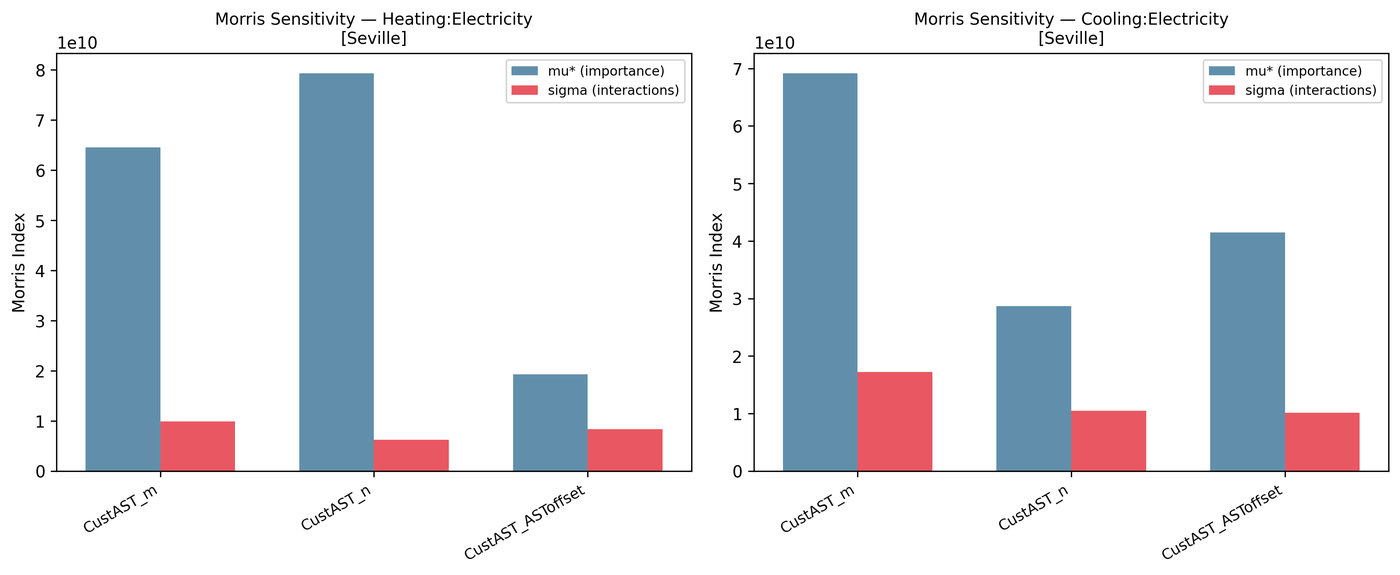

In [6]:

sa_morris = parametric.run_sensitivity_analysis(method="morris")
print("Morris SA outputs:", list(sa_morris.keys()))

sa_morris_by_epw = parametric.run_sensitivity_analysis_by_epw(
    method="morris",
    out_dir=RESULTS_DIRNAME,
)
print("Morris SA by EPW:", list(sa_morris_by_epw.keys()))

# Figure saved by run_sensitivity_analysis_by_epw, one per EPW.
for figure in sorted(Path(RESULTS_DIRNAME).glob("plot_sa_morris_*.png")):
    display(Image(filename=str(figure)))


### Reading the result

Use the strongest sensitivity indices as guidance for parameter-range refinement in the next iteration.

## Sampling and sensitivity: inspect generated artifacts before cleanup

This section audits generated artifacts and applies the configured cleanup policy.

Keeping cleanup explicit avoids accidental deletion while still preventing accumulation of stale run artifacts.

Key arguments used in this cell and why they matter:
- `max_items`: maximum number of items shown in logs.

Variables created in this cell:
- `generated_files`: reused in subsequent workflow blocks.

What to verify right after running this cell:
- Confirm these objects are available for the next block: `generated_files`.

In [7]:
generated_files = artifact_cleaner.print_generated_files(max_items=200)


Generated files detected: 6
 - nb05_sampling_sensitivity_results/accim_idf_backup_OSM_TestResidentialUnit_v01_onlygeometry_SchNatVent_v2520_high_performance_pre_parametric_20261016_004605.idf
 - nb05_sampling_sensitivity_results/outputs_param_simulation_20261016_004704.csv
 - nb05_sampling_sensitivity_results/outputs_param_simulation_20261016_004704.json
 - nb05_sampling_sensitivity_results/outputs_param_simulation_20261016_004704.pkl
 - nb05_sampling_sensitivity_results/outputs_param_simulation_20261016_004704.xlsx
 - nb05_sampling_sensitivity_results/outputs_param_simulation_batches/outputs_param_simulation_batch_00001_20261016_004703_795158.pkl


This section audits generated artifacts and applies the configured cleanup policy.

Keeping cleanup explicit avoids accidental deletion while still preventing accumulation of stale run artifacts.

Key arguments used in this cell and why they matter:
- `allow_patterns`: file patterns that are allowed for cleanup.
- `deny_patterns`: file patterns protected from cleanup.
- `dry_run`: whether cleanup only reports actions without deleting.
- `remove_empty_dirs`: whether empty directories are removed after cleanup.

What to verify right after running this cell:
- Review execution output and proceed when values look consistent with the workflow intent.

In [8]:
artifact_cleaner.delete_generated_files(
	allow_patterns=[f"{RESULTS_DIRNAME}/**"],
	deny_patterns=[],
	dry_run=True,
	remove_empty_dirs=True,
)


Files planned for deletion: 6
 - nb05_sampling_sensitivity_results/accim_idf_backup_OSM_TestResidentialUnit_v01_onlygeometry_SchNatVent_v2520_high_performance_pre_parametric_20261016_004605.idf
 - nb05_sampling_sensitivity_results/outputs_param_simulation_20261016_004704.csv
 - nb05_sampling_sensitivity_results/outputs_param_simulation_20261016_004704.json
 - nb05_sampling_sensitivity_results/outputs_param_simulation_20261016_004704.pkl
 - nb05_sampling_sensitivity_results/outputs_param_simulation_20261016_004704.xlsx
 - nb05_sampling_sensitivity_results/outputs_param_simulation_batches/outputs_param_simulation_batch_00001_20261016_004703_795158.pkl
Dry run enabled. No files were deleted.


['nb05_sampling_sensitivity_results/accim_idf_backup_OSM_TestResidentialUnit_v01_onlygeometry_SchNatVent_v2520_high_performance_pre_parametric_20261016_004605.idf',
 'nb05_sampling_sensitivity_results/outputs_param_simulation_20261016_004704.csv',
 'nb05_sampling_sensitivity_results/outputs_param_simulation_20261016_004704.json',
 'nb05_sampling_sensitivity_results/outputs_param_simulation_20261016_004704.pkl',
 'nb05_sampling_sensitivity_results/outputs_param_simulation_20261016_004704.xlsx',
 'nb05_sampling_sensitivity_results/outputs_param_simulation_batches/outputs_param_simulation_batch_00001_20261016_004703_795158.pkl']

## Sampling and sensitivity: remove generated artifacts from this run

This section audits generated artifacts and applies the configured cleanup policy.

Keeping cleanup explicit avoids accidental deletion while still preventing accumulation of stale run artifacts.

`DELETE_RESULTS` is False by default, so nothing is deleted. Set it to True to delete the files listed above.

Key arguments used in this cell and why they matter:
- `allow_patterns`: file patterns that are allowed for cleanup.
- `deny_patterns`: file patterns protected from cleanup.
- `dry_run`: whether cleanup only reports actions without deleting.
- `remove_empty_dirs`: whether empty directories are removed after cleanup.

What to verify right after running this cell:
- Review execution output and proceed when values look consistent with the workflow intent.

In [9]:
DELETE_RESULTS = False

if DELETE_RESULTS:
    artifact_cleaner.delete_generated_files(
        allow_patterns=[f"{RESULTS_DIRNAME}/**"],
        deny_patterns=[],
        dry_run=False,
        remove_empty_dirs=True,
    )
